<a href="https://colab.research.google.com/github/alexagtzs06/pdi/blob/main/practica4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imágenes cargadas exitosamente.


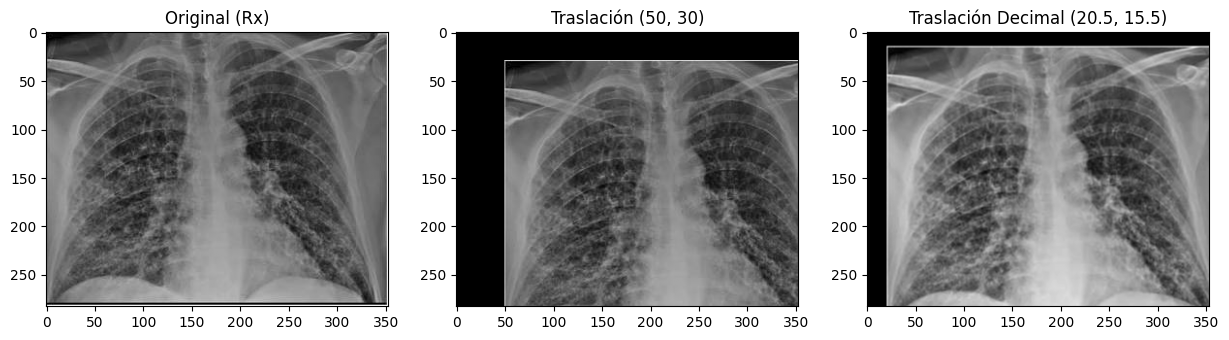

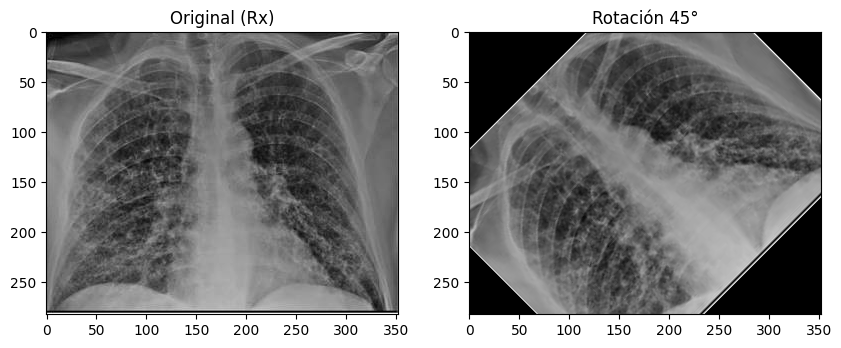

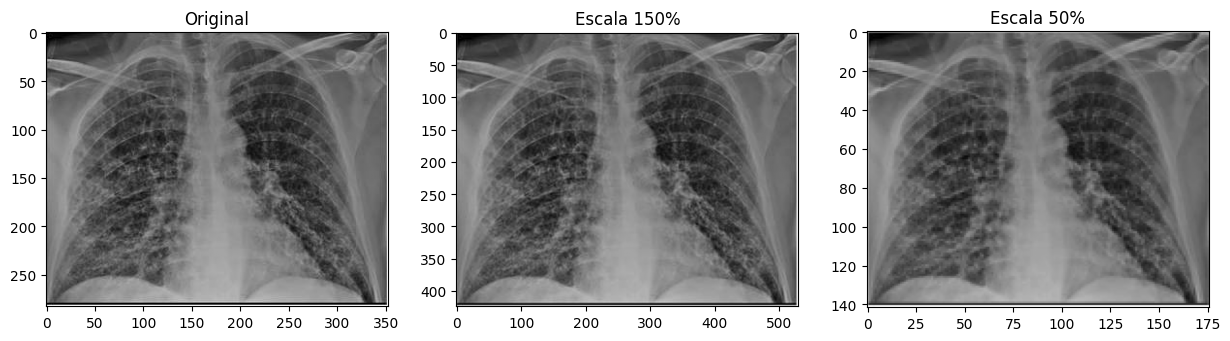

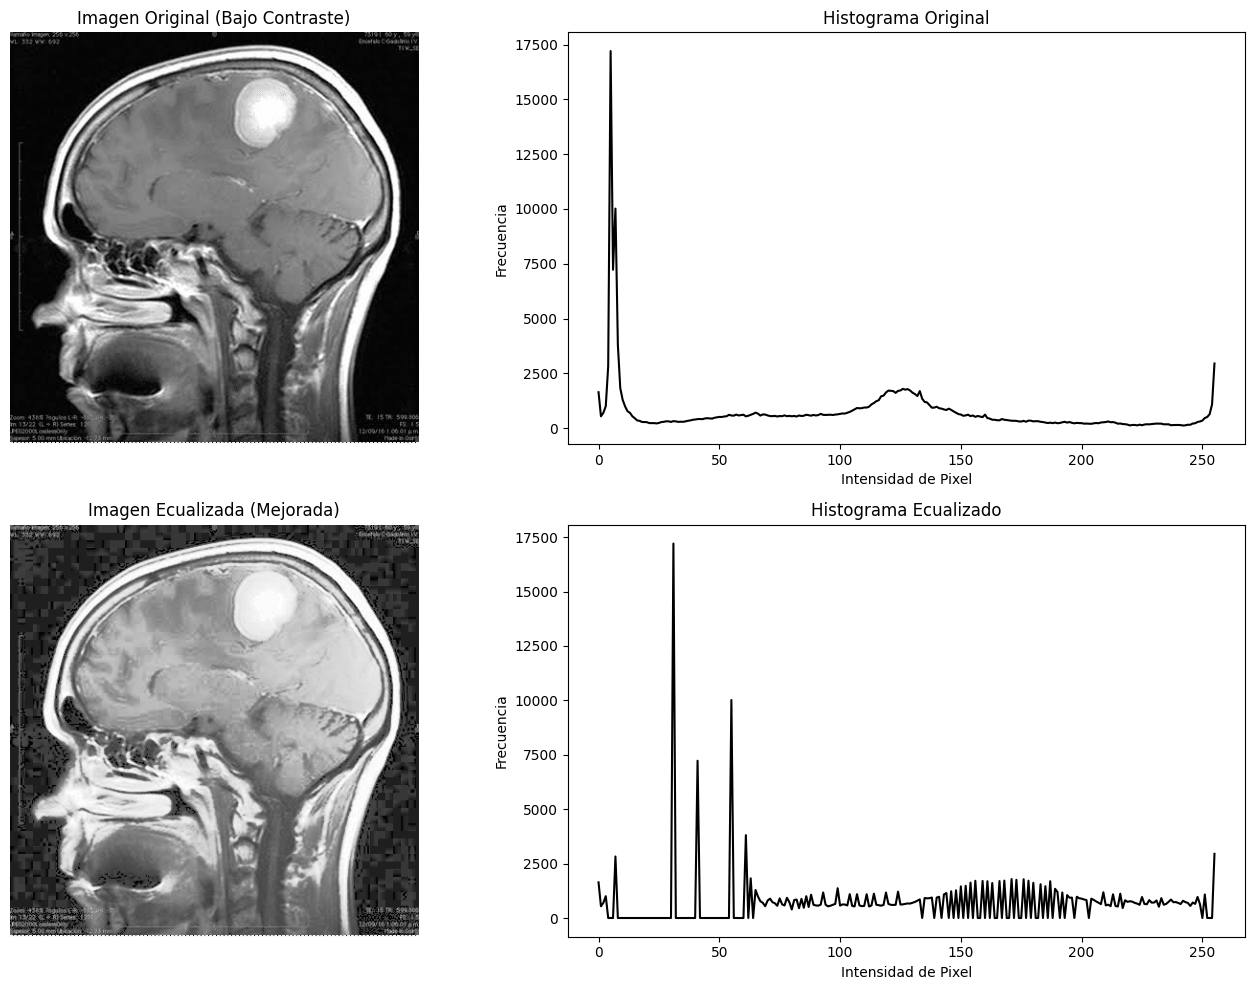

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar imágenes médicas en escala de grises
# Nota: Reemplazar con las rutas de las imágenes médica utilizadas (ej. rayos X y resonancia)
img_geo = cv2.imread('practica4.jpg', cv2.IMREAD_GRAYSCALE)
img_hist = cv2.imread('practica4pt2.jpg', cv2.IMREAD_GRAYSCALE)

# Validar carga correcta
if img_geo is None or img_hist is None:
  print(
      'Error al cargar las imágenes. Verifique las rutas o nombres de archivo.'
  )
else:
  print('Imágenes cargadas exitosamente.')

# ==========================================
# PARTE I: PROCESAMIENTO GEOMÉTRICO
# ==========================================

# --- Ejercicio 1: Traslación ---
rows, cols = img_geo.shape

# 1.1 Traslación entera de (50, 30) píxeles en (x, y)
M_entera = np.float32([[1, 0, 50], [0, 1, 30]])
img_traslada_entera = cv2.warpAffine(img_geo, M_entera, (cols, rows))

# 1.2 Traslación con valores decimales (20.5, 15.5) píxeles
M_decimal = np.float32([[1, 0, 20.5], [0, 1, 15.5]])
img_traslada_decimal = cv2.warpAffine(
    img_geo, M_decimal, (cols, rows), flags=cv2.INTER_LINEAR
)

# Visualización Ejercicio 1
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(img_geo, cmap='gray'), plt.title(
    'Original (Rx)'
)
plt.subplot(1, 3, 2), plt.imshow(
    img_traslada_entera, cmap='gray'
), plt.title('Traslación (50, 30)')
plt.subplot(1, 3, 3), plt.imshow(
    img_traslada_decimal, cmap='gray'
), plt.title('Traslación Decimal (20.5, 15.5)')
plt.show()

# --- Ejercicio 2: Rotación de 45° ---
center = (cols / 2, rows / 2)
angle = 45
scale = 1.0
M_rot = cv2.getRotationMatrix2D(center, angle, scale)
img_rotada = cv2.warpAffine(
    img_geo, M_rot, (cols, rows), flags=cv2.INTER_LINEAR
)

# Visualización Ejercicio 2
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(img_geo, cmap='gray'), plt.title(
    'Original (Rx)'
)
plt.subplot(1, 2, 2), plt.imshow(img_rotada, cmap='gray'), plt.title(
    'Rotación 45°'
)
plt.show()

# --- Ejercicio 3: Escalado (150% y 50%) ---
# 150% de escala
img_150 = cv2.resize(
    img_geo, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC
)
# 50% de escala
img_50 = cv2.resize(
    img_geo, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA
)

# Visualización Ejercicio 3
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(img_geo, cmap='gray'), plt.title('Original')
plt.subplot(1, 3, 2), plt.imshow(img_150, cmap='gray'), plt.title(
    'Escala 150%'
)
plt.subplot(1, 3, 3), plt.imshow(img_50, cmap='gray'), plt.title('Escala 50%')
plt.show()

# ==========================================
# PARTE II: ECUALIZACIÓN DE HISTOGRAMA
# ==========================================

# 1. Cargar imagen médica con bajo contraste
img_lc = img_hist  # Usamos la imagen de resonancia cargada

# 2. Obtener y visualizar histograma original
hist_orig = cv2.calcHist([img_lc], [0], None, [256], [0, 256])

# 3. Aplicar ecualización de histograma
img_eq = cv2.equalizeHist(img_lc)
hist_eq = cv2.calcHist([img_eq], [0], None, [256], [0, 256])

# 4. Mostrar imágenes y comparar histogramas
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(img_lc, cmap='gray')
plt.title('Imagen Original (Bajo Contraste)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.plot(hist_orig, color='black')
plt.title('Histograma Original')
plt.xlabel('Intensidad de Pixel')
plt.ylabel('Frecuencia')

plt.subplot(2, 2, 3)
plt.imshow(img_eq, cmap='gray')
plt.title('Imagen Ecualizada (Mejorada)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.plot(hist_eq, color='black')
plt.title('Histograma Ecualizado')
plt.xlabel('Intensidad de Pixel')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()